# 03 · TF-IDF and Random Forest baseline
Train on development training rows, evaluate on JD-grouped validation. The final refitted model has a separate untouched-test report.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
import numpy as np
def read_json(path): return json.loads((ROOT/path).read_text())

In [2]:
from resume_matcher.model import ResumeJDMatcher
from sklearn.metrics import classification_report
train=pd.read_csv(ROOT/'data/processed/train.csv')
validation=pd.read_csv(ROOT/'data/processed/validation.csv')
baseline=ResumeJDMatcher().fit(train)
x=baseline._feature_matrix(validation.resume_text,validation.jd_text)
pred=baseline.label_encoder.inverse_transform(baseline.classifier.predict(x))
print(classification_report(validation.label,pred,zero_division=0))
print(baseline.classifier.get_params())

               precision    recall  f1-score   support

      low_fit       0.55      0.82      0.66       573
potential_fit       0.32      0.20      0.24       305
   strong_fit       0.41      0.21      0.28       325

     accuracy                           0.49      1203
    macro avg       0.43      0.41      0.39      1203
 weighted avg       0.45      0.49      0.45      1203

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 250, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


Final source-train refit, untouched test: {'accuracy': 0.4673109721432632, 'macro_f1': 0.3626226612418131, 'weighted_f1': 0.42004938963881033}


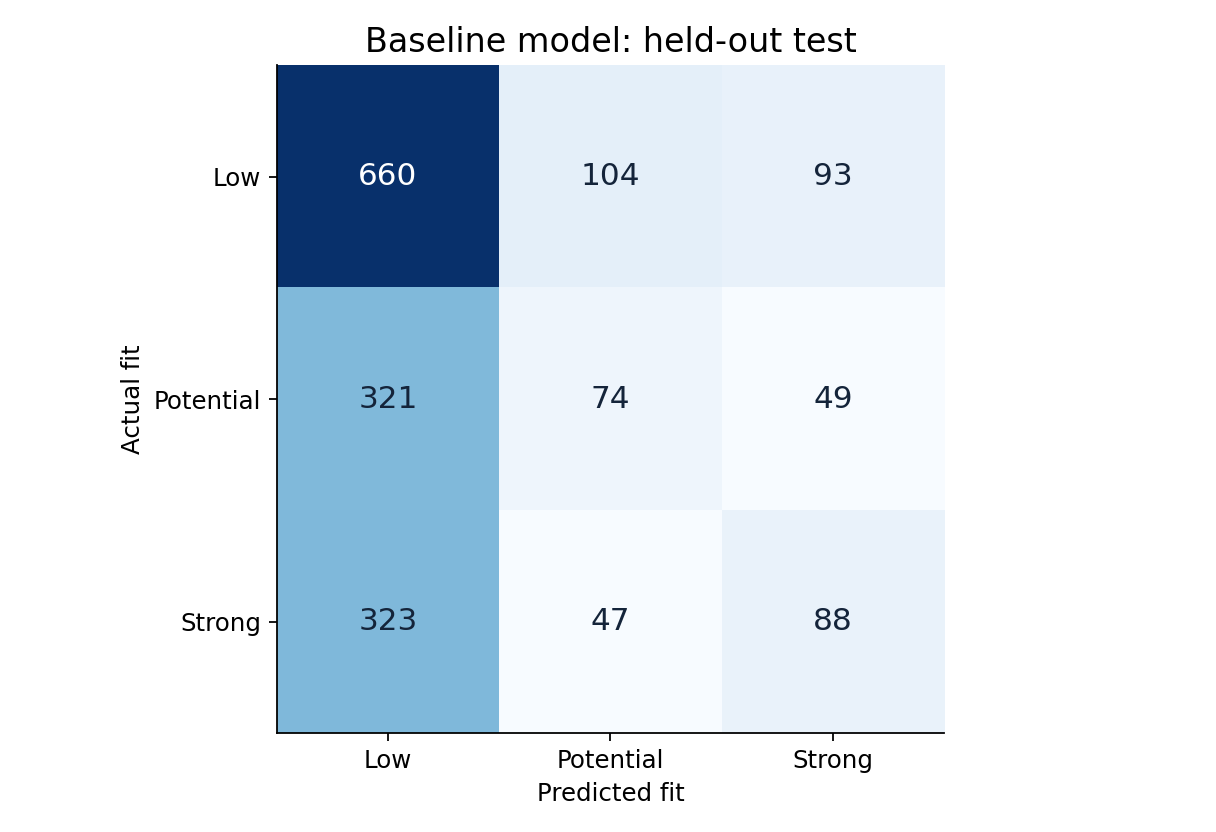

In [3]:
metrics=read_json('reports/metrics.json')
print('Final source-train refit, untouched test:',{k:metrics['baseline'][k] for k in ['accuracy','macro_f1','weighted_f1']})
from IPython.display import display, Image
display(Image(filename=str(ROOT/'reports/figures/baseline_confusion_matrix.png')))

TF-IDF captures lexical overlap. Eight numeric features summarize cosine, skill/token overlap and relative lengths. Class balancing cannot remove label noise or prove fairness. The majority baseline is included to avoid interpreting accuracy in isolation.